# Maize Leaf Disease Classification
**Steven Kayitare** | African Leadership University | MLOps Summative

This notebook builds the offline model for the pipeline. The process is to take photos of maize leaves, sort them into four health classes, run three experiments, pick the best one, evaluate it properly and save it. The saved model is what the deployment and retraining pipeline loads later as a pre-trained model.

Classes: Blight, Common Rust, Gray Leaf Spot, Healthy.
Dataset: Corn or Maize Leaf Disease (Kaggle, smaranjitghose), about 4,188 images curated from PlantVillage and PlantDoc.


*Link to dataset:* https://www.kaggle.com/datasets/smaranjitghose/corn-or-maize-leaf-disease-dataset

## Environment setup

Importing all necessary libraries to be used

In [7]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

tf.random.set_seed(42)
np.random.seed(42)
print("tensorflow", tf.__version__)

tensorflow 2.21.0


## Mount Drive
The data lives in my Google Drive under `maize_data`. I mount the drive and point at that folder. The four class folders sit directly inside it.

In [8]:
from google.colab import drive
drive.mount('/content/drive')

data_dir = '/content/drive/MyDrive/maize_data'
os.listdir(data_dir)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


['Healthy', 'Blight', 'Common_Rust', 'Gray_Leaf_Spot']

## Load the dataset


In [9]:
img_size = (160, 160)
batch = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=img_size,
    batch_size=batch,
)

rest_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=img_size,
    batch_size=batch,
)

class_names = train_ds.class_names

rest_batches = tf.data.experimental.cardinality(rest_ds)
test_ds = rest_ds.take(rest_batches // 2)
val_ds = rest_ds.skip(rest_batches // 2)

print("classes:", class_names)
print("train batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("val batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("test batches:", tf.data.experimental.cardinality(test_ds).numpy())

Found 4188 files belonging to 4 classes.
Using 3351 files for training.
Found 4188 files belonging to 4 classes.
Using 837 files for validation.
classes: ['Blight', 'Common_Rust', 'Gray_Leaf_Spot', 'Healthy']
train batches: 105
val batches: 14
test batches: 13


## One image per class
A quick look at the images

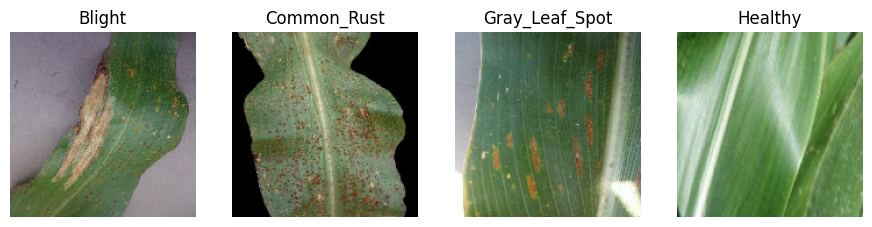

In [10]:
def show_one_per_class(ds, names):
    seen = {}
    for image, label in ds.unbatch():
        label = int(label)
        if label not in seen:
            seen[label] = image.numpy().astype("uint8")
        if len(seen) == len(names):
            break
    plt.figure(figsize=(11, 3))
    for i, name in enumerate(names):
        plt.subplot(1, len(names), i + 1)
        plt.imshow(seen[i])
        plt.title(name)
        plt.axis("off")
    plt.show()

show_one_per_class(train_ds, class_names)

## Exploratory Dara Analysis (EDA)


###  Class distribution
Counting the images in each folder to tell whether the classes are balanced, which decides how I will read the metrics later.

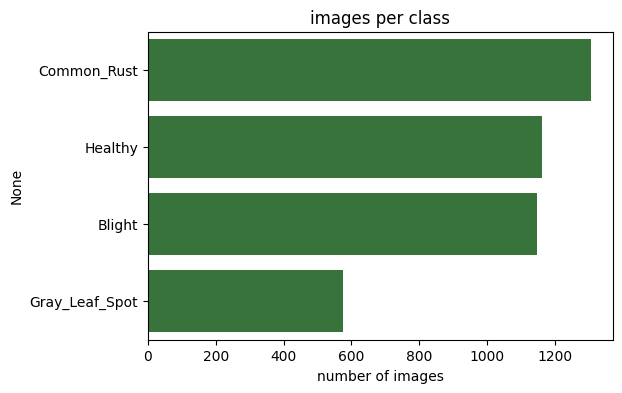

,0
Common_Rust,1306
Healthy,1162
Blight,1146
Gray_Leaf_Spot,574


In [11]:
counts = {name: len(os.listdir(os.path.join(data_dir, name))) for name in class_names}
dist = pd.Series(counts).sort_values(ascending=False)

plt.figure(figsize=(6, 4))
sns.barplot(x=dist.values, y=dist.index, color="#2e7d32")
plt.xlabel("number of images")
plt.title("images per class")
plt.show()

dist

The classes are not balanced. Gray Leaf Spot has the fewest images and Common Rust the most, so plain accuracy would flatter the big classes. That is why we track macro F1 alongside accuracy, since it weighs every class equally.

### Image size and aspect ratio
The photos do not all arrive at the same resolution. Plotting width against height shows how spread out they are and explains why a resize step is needed before anything reaches the model.

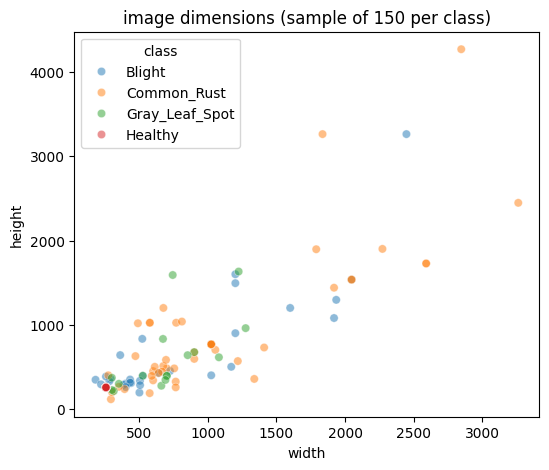

,width,height
count,600.00000,600.000000
mean,358.47000,338.820000
std,353.09353,341.270181
min,180.00000,116.000000
25%,256.00000,256.000000
50%,256.00000,256.000000
75%,256.00000,256.000000
max,3264.00000,4272.000000


In [12]:
rows = []
for name in class_names:
    folder = os.path.join(data_dir, name)
    for fname in os.listdir(folder)[:150]:
        w, h = tf.keras.utils.load_img(os.path.join(folder, fname)).size
        rows.append((name, w, h))

sizes = pd.DataFrame(rows, columns=["class", "width", "height"])

plt.figure(figsize=(6, 5))
sns.scatterplot(data=sizes, x="width", y="height", hue="class", alpha=0.5)
plt.title("image dimensions (sample of 150 per class)")
plt.show()

sizes[["width", "height"]].describe()

The points scatter across many resolutions instead of sitting on one spot, so the raw images are inconsistent in size. That is why we fix every image to 160x160 at load time. Without it the network could not stack them into a batch.

### Colour profile per class
Leaf disease shows up as a colour change, so the average red, green and blue of each class is a feature worth checking. We resize a sample to one common size, average each channel, and compare across the four classes.

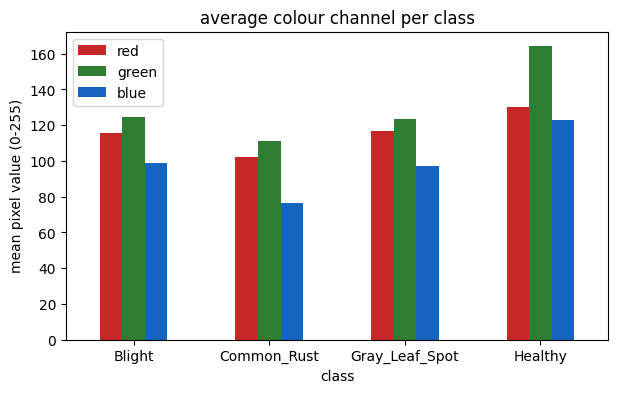

,red,green,blue
class,,,
Blight,115.525467,124.303452,98.634331
Common_Rust,102.220337,111.038376,76.225700
Gray_Leaf_Spot,116.715157,123.520134,96.834938
Healthy,130.001297,164.085007,122.628189


In [13]:
rows = []
for name in class_names:
    folder = os.path.join(data_dir, name)
    for fname in os.listdir(folder)[:150]:
        img = tf.keras.utils.load_img(os.path.join(folder, fname), target_size=(160, 160))
        arr = tf.keras.utils.img_to_array(img)
        rows.append((name, arr[..., 0].mean(), arr[..., 1].mean(), arr[..., 2].mean()))

colors = pd.DataFrame(rows, columns=["class", "red", "green", "blue"])
means = colors.groupby("class")[["red", "green", "blue"]].mean()

means.plot(kind="bar", color=["#c62828", "#2e7d32", "#1565c0"], figsize=(7, 4))
plt.title("average colour channel per class")
plt.ylabel("mean pixel value (0-255)")
plt.xticks(rotation=0)
plt.show()

means

Healthy leaves carry the most green, while Common Rust and Blight push red up and green down as the tissue browns. Gray Leaf Spot sits between them. This colour separation is a real signal in the data and a large part of what the CNN keys on to tell the classes apart.

## Preprocessing
Two things happen before training. Caching and prefetching the datasets so the GPU is not waiting on disk, and each model gets light augmentation (flip, small rotation, small zoom) built into it so it sees more variety without us copying files around. Normalization is handled inside each model too.

In [14]:
autotune = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(autotune)
val_ds = val_ds.cache().prefetch(autotune)
test_ds = test_ds.cache().prefetch(autotune)
print("datasets cached and prefetched")

datasets cached and prefetched


## A helper to train a model
All three experiments compile the same way (Adam, sparse categorical crossentropy) and train with early stopping so they quit once validation stops improving.

In [15]:
def run_model(model, name, epochs=15):
    model.compile(
        optimizer="adam",
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"],
    )
    stop = EarlyStopping(patience=4, restore_best_weights=True)
    history = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=[stop])
    print(name, "done")
    return history

## Experiment 1: baseline CNN
A plain convolutional network trained from scratch, no augmentation. This is a baseline model, the number the other two have to beat.

In [16]:
def build_baseline():
    return models.Sequential([
        layers.Input(shape=img_size + (3,)),
        layers.Rescaling(1./255),
        layers.Conv2D(16, 3, activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(32, 3, activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation="relu"),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dense(len(class_names), activation="softmax"),
    ])

baseline = build_baseline()
hist_baseline = run_model(baseline, "baseline cnn", epochs=15)

Epoch 1/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 33s 208ms/step - accuracy: 0.7472 - loss: 0.6406 - val_accuracy: 0.8551 - val_loss: 0.3696
Epoch 2/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.8144 - loss: 0.4460 - val_accuracy: 0.8670 - val_loss: 0.3420
Epoch 3/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.8609 - loss: 0.3346 - val_accuracy: 0.8717 - val_loss: 0.3024
Epoch 4/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.8890 - loss: 0.2781 - val_accuracy: 0.8907 - val_loss: 0.2739
Epoch 5/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9099 - loss: 0.2308 - val_accuracy: 0.8789 - val_loss: 0.3157
Epoch 6/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9170 - loss: 0.1998 - val_accuracy: 0.9050 - val_loss: 0.2817
Epoch 7/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9409 - loss: 0.1610 - val_accuracy: 0.8979 - val_loss: 0.3061
Epoch 8/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9514 - loss: 0.1376 - val_ac

## Experiment 2: regularized CNN
Same idea but hardened against overfitting: augmentation up front, batch normalization between conv blocks, and dropout before the output. I expect this to generalize better than the baseline.

In [17]:
def build_reg_cnn():
    return models.Sequential([
        layers.Input(shape=img_size + (3,)),
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1),
        layers.Rescaling(1./255),
        layers.Conv2D(32, 3, activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),
        layers.Conv2D(128, 3, activation="relu"),
        layers.MaxPooling2D(),
        layers.Dropout(0.3),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.4),
        layers.Dense(len(class_names), activation="softmax"),
    ])

reg_cnn = build_reg_cnn()
hist_reg = run_model(reg_cnn, "regularized cnn", epochs=20)

Epoch 1/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 16s 76ms/step - accuracy: 0.6995 - loss: 1.4088 - val_accuracy: 0.2565 - val_loss: 1.5420
Epoch 2/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 7s 68ms/step - accuracy: 0.8087 - loss: 0.4720 - val_accuracy: 0.3539 - val_loss: 1.7935
Epoch 3/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 7s 66ms/step - accuracy: 0.8087 - loss: 0.4336 - val_accuracy: 0.4323 - val_loss: 2.9176
Epoch 4/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 7s 68ms/step - accuracy: 0.8069 - loss: 0.4484 - val_accuracy: 0.5226 - val_loss: 1.0183
Epoch 5/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 7s 67ms/step - accuracy: 0.8102 - loss: 0.4491 - val_accuracy: 0.7672 - val_loss: 0.6156
Epoch 6/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 7s 67ms/step - accuracy: 0.8239 - loss: 0.4176 - val_accuracy: 0.8314 - val_loss: 0.3285
Epoch 7/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 7s 65ms/step - accuracy: 0.8147 - loss: 0.4124 - val_accuracy: 0.8290 - val_loss: 0.4025
Epoch 8/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 7s 67ms/step - accuracy: 0.8263 - loss: 0.3789 - val_acc

## Experiment 3: transfer learning with MobileNetV2
Using a network already trained on ImageNet, freeze it, and train a small head on top of our four classes. Then, unfreeze the last few layers and fine-tune at a tiny learning rate so the features shift toward leaves. This is the model most likely to win and the one built to be reused as a pre-trained model in retraining.

In [18]:
def build_transfer():
    base = MobileNetV2(input_shape=img_size + (3,), include_top=False, weights="imagenet")
    base.trainable = False

    inputs = layers.Input(shape=img_size + (3,))
    x = layers.RandomFlip("horizontal")(inputs)
    x = layers.RandomRotation(0.1)(x)
    x = layers.RandomZoom(0.1)(x)
    x = preprocess_input(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(len(class_names), activation="softmax")(x)
    return models.Model(inputs, outputs), base

transfer, base = build_transfer()
hist_transfer = run_model(transfer, "mobilenetv2 frozen", epochs=12)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/12
105/105 ━━━━━━━━━━━━━━━━━━━━ 13s 70ms/step - accuracy: 0.7807 - loss: 0.5795 - val_accuracy: 0.8741 - val_loss: 0.3095
Epoch 2/12
105/105 ━━━━━━━━━━━━━━━━━━━━ 4s 34ms/step - accuracy: 0.8962 - loss: 0.2776 - val_accuracy: 0.8931 - val_loss: 0.2659
Epoch 3/12
105/105 ━━━━━━━━━━━━━━━━━━━━ 4s 34ms/step - accuracy: 0.9090 - loss: 0.2404 - val_accuracy: 0.9050 - val_loss: 0.2360
Epoch 4/12
105/105 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - accuracy: 0.9102 - loss: 0.2297 - val_accuracy: 0.9050 - val_loss: 0.2262
Epoch 5/12
105/105 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - accuracy: 0.9257 - loss: 0.1979 - val_accuracy: 0.9050 - val_loss: 0.2087
Epoch 6/12
105/105 ━━━━━━━━━━━━━━━━━━━━ 4s 35ms/step - accuracy: 0.9287 - loss: 0.1877 - val_accuracy: 0.9192 - val_loss: 0.2008
Epoch 7/12
105/105 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.9221 - loss: 0.1896 - val_accuracy: 0.9097 - val_loss: 0.2123
Epoch 8/12
105/105 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms

Now the fine-tuning pass: unfreeze the top of the base and keep training gently.

In [19]:
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False

transfer.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)
stop = EarlyStopping(patience=3, restore_best_weights=True)
hist_finetune = transfer.fit(train_ds, validation_data=val_ds, epochs=6, callbacks=[stop])

Epoch 1/6
105/105 ━━━━━━━━━━━━━━━━━━━━ 15s 67ms/step - accuracy: 0.8860 - loss: 0.2995 - val_accuracy: 0.9121 - val_loss: 0.2083
Epoch 2/6
105/105 ━━━━━━━━━━━━━━━━━━━━ 5s 44ms/step - accuracy: 0.9138 - loss: 0.2319 - val_accuracy: 0.9169 - val_loss: 0.2123
Epoch 3/6
105/105 ━━━━━━━━━━━━━━━━━━━━ 5s 44ms/step - accuracy: 0.9135 - loss: 0.2148 - val_accuracy: 0.9145 - val_loss: 0.2224
Epoch 4/6
105/105 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - accuracy: 0.9141 - loss: 0.2156 - val_accuracy: 0.9264 - val_loss: 0.2213


## Compare the three experiments
Each model is scored on the held-out test set with accuracy and macro F1.

In [20]:
def evaluate_model(model):
    y_true = np.concatenate([y.numpy() for x, y in test_ds])
    y_pred = model.predict(test_ds).argmax(axis=1)
    return accuracy_score(y_true, y_pred), f1_score(y_true, y_pred, average="macro")

scores = {
    "baseline cnn": evaluate_model(baseline),
    "regularized cnn": evaluate_model(reg_cnn),
    "mobilenetv2": evaluate_model(transfer),
}

results = pd.DataFrame(scores, index=["accuracy", "macro_f1"]).T.sort_values("macro_f1", ascending=False)
results

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step


,accuracy,macro_f1
mobilenetv2,0.913462,0.895752
baseline cnn,0.870192,0.839700
regularized cnn,0.824519,0.696576


In [21]:
best_name = results.index[0]
best_model = {"baseline cnn": baseline, "regularized cnn": reg_cnn, "mobilenetv2": transfer}[best_name]
print("best model:", best_name)

best model: mobilenetv2


## Evaluate the best model
The classification report gives precision, recall and F1 for every class plus overall accuracy, so I can see exactly where the model is strong and where it slips.

In [22]:
y_true = np.concatenate([y.numpy() for x, y in test_ds])
y_pred = best_model.predict(test_ds).argmax(axis=1)

print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
                precision    recall  f1-score   support

        Blight      0.891     0.831     0.860       118
   Common_Rust      0.947     0.973     0.960       111
Gray_Leaf_Spot      0.735     0.794     0.763        63
       Healthy      1.000     1.000     1.000       124

      accuracy                          0.913       416
     macro avg      0.893     0.899     0.896       416
  weighted avg      0.915     0.913     0.914       416



## Confusion matrix
Where the mistakes actually land, class by class.

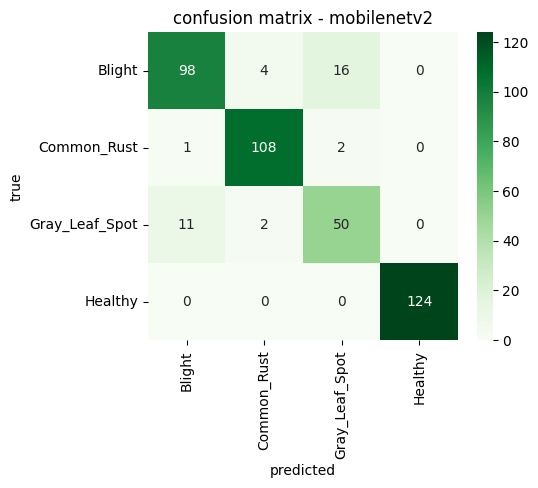

In [23]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("predicted")
plt.ylabel("true")
plt.title("confusion matrix - " + best_name)
plt.show()

## Training curves
Loss and accuracy over epochs for the best model, to check it learned cleanly and did not overfit.

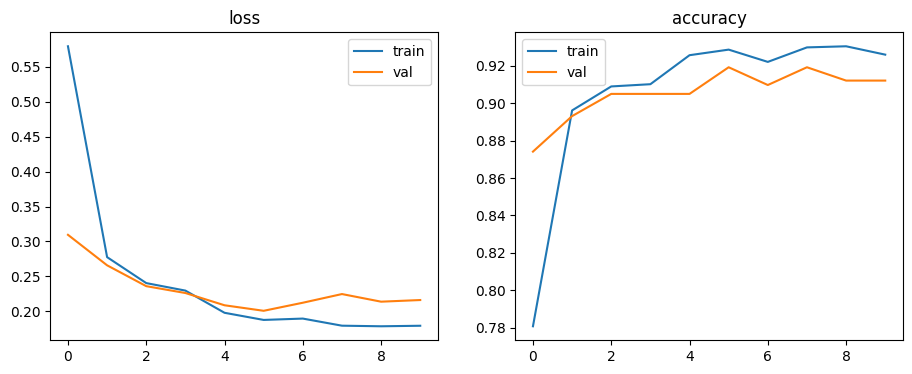

In [24]:
histories = {
    "baseline cnn": hist_baseline,
    "regularized cnn": hist_reg,
    "mobilenetv2": hist_transfer,
}
h = histories[best_name].history

plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1)
plt.plot(h["loss"], label="train")
plt.plot(h["val_loss"], label="val")
plt.title("loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(h["accuracy"], label="train")
plt.plot(h["val_accuracy"], label="val")
plt.title("accuracy")
plt.legend()
plt.show()

## Save the model
Save the winner to Drive. This single file is what the prediction API loads to classify one leaf, and what the retraining pipeline loads as the pre-trained starting point when a user uploads new data.

In [25]:
save_path = '/content/drive/MyDrive/maize_data/maize_model.keras'
best_model.save(save_path)
print("saved to", save_path)

saved to /content/drive/MyDrive/maize_data/maize_model.keras


## Next
With the model saved, the rest of the pipeline is: `src/preprocessing.py`, `src/model.py` and `src/prediction.py` pulled out of this notebook, the web app exposing prediction and retraining, bulk upload to trigger retraining, and the Locust flood test. Those come next, one piece at a time.